### Planned Steps & Workflow (Referencing `docs/project_cv_workflow.html`)
**Model ladder rungs: M2, M3, M4** (each rung adds one change on top of the previous one; order decided by the group)
- **1. Setup & Remediation Plan**:
  - Load the base processed training dataset (`data/train_base.csv`) and shared expanding-window CV protocol ($k=8$ monthly folds).
  - Load the catalog of base-model mistakes identified in Notebook 03.
- **2. Model-Specific Processing (built in this notebook)**:
  - *Log target*: Model on $\log(cnt)$ scale.
  - *Polynomial terms*: e.g. quadratic temperature ($\text{temp}^2$).
  - *Interaction terms*: e.g. $\text{hr} \times \text{workingday}$.
- **3. Ladder Candidates**:
  - Fit each rung as its own candidate so the CV gain from each change is measured separately.
- **4. Back-Transformation (Feedback #8)**:
  - Back-transform log-scale predictions with correction ($\exp(\hat{y} + \hat{\sigma}^2/2)$) inside CV folds for count-scale evaluation.
- **5. Shared Expanding-Window CV Comparison (Workflow Step 5)**:
  - Run all rungs through the shared CV folds with the fixed metric.
  - Record mean CV error and $\text{SE} = \text{SD} / \sqrt{8}$ for each rung.
- **6. Diagnostic Verification of Resolved Mistakes**:
  - Re-evaluate Residuals vs. Fitted, Scale-Location, and Q-Q plots to verify that base-model mistakes are addressed.
  - Identify remaining challenges (e.g. high dimensionality from interactions) to pass to Notebook 05.

## 1. Setup and Data Ingestion
*Code: Generated by AI Assistant*

This notebook reads the base processed training set only (`data/train_base.csv`, written by Notebook 02). The locked test set is **not** touched (it is read once, in Notebook 06).
- Predictors: 48 base columns (43 dummies + 2 binary + 3 numeric): the Notebook 02 base set without the `holiday` column. `workingday` stays as a main effect and is the variable used in the `hr` $\times$ `workingday` interaction. `dteday` is kept only as the date key for the CV splitter and diagnostics.
- CV protocol: the shared `ExpandingWindowSplit` ($k = 8$ monthly folds, Feb 2012 to Sep 2012) from `src/cv_utils.py`.
- Metric: count-scale MSE / RMSE, with $\text{SE} = \text{SD of fold errors} / \sqrt{k}$.

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Ensure local source modules can be imported
sys.path.append(os.path.abspath('..'))
from src.data_utils import load_train_base, BASE_TRAIN_PATH
from src.cv_utils import get_cv_splitter, FIRST_VAL_MONTH, LAST_VAL_MONTH

sns.set_style('whitegrid')

# Load the base processed training set (written by Notebook 02)
base_df = load_train_base()
print(f"Base training set loaded. Shape: {base_df.shape}")

# Column roles (from Notebook 02)
ID_COLS = ['dteday']
TARGET = 'cnt'
# Group decision: `holiday` is NOT a main-effect predictor.
# workingday = weekday_1..5 - holiday exactly, so keeping all three makes the design rank-deficient
# (individual coefficients not unique). Dropping holiday restores full rank and keeps workingday as an
# explicit main effect next to the hr x workingday interaction (hierarchy principle, I-02).
FEATURE_COLS = [c for c in base_df.columns if c not in ID_COLS + [TARGET, 'holiday']]
WEEKDAY_WD_COLS = [f'weekday_{d}' for d in range(1, 6)]            # Mon-Fri dummies (Sunday = reference)
assert ((base_df[WEEKDAY_WD_COLS].astype(int).sum(axis=1) - base_df['holiday'].astype(int))
        == base_df['workingday']).all(), 'workingday is not exactly weekday_1..5 minus holiday'
HR_COLS = [c for c in FEATURE_COLS if c.startswith('hr_')]


# Shared expanding-window CV splitter (identical to Notebook 02 / 03)
cv_splitter = get_cv_splitter(base_df['dteday'])
K = cv_splitter.get_n_splits()
print(f"Shared CV Splitter: ExpandingWindowSplit ({K} monthly folds, {FIRST_VAL_MONTH} to {LAST_VAL_MONTH})")
print(f"Predictors: {len(FEATURE_COLS)} | Target: {TARGET} (min = {base_df[TARGET].min()}, max = {base_df[TARGET].max()})")

Base training set loaded. Shape: (15211, 51)
Shared CV Splitter: ExpandingWindowSplit (8 monthly folds, 2012-02 to 2012-09)
Predictors: 48 | Target: cnt (min = 1, max = 977)




Each remedy below targets one diagnosed failure of the base OLS (M1, Notebook 03).

| # | Mistake in M1 | Evidence | Remedy | Rung |
| :-- | :--- | :--- | :--- | :--- |
| 1 | Right-skewed target, funnel-shaped residuals (heteroskedasticity) | EDA  (skew, $\text{Var} \gg \text{Mean}$); Scale-Location plot (03) | Model $\log(cnt)$, back-transform with $\exp(\hat{y} + \hat{\sigma}^2/2)$ | **M2** |
| 2 | Negative predicted demand ($\hat{y} < 0$) | Count of negative predictions (03) | Log target: $\exp(\cdot) > 0$ always | **M2** |
| 3 | Curvature in `temp`, `hum`, `windspeed` | EDA scatter trendlines; added-variable plots (03) | Add squared terms | **M3** |
| 4 | One hourly profile forced on working days and weekends | EDA (twin peaks vs single midday hump); residuals by hour $\times$ working day (03) | Interaction `hr` $\times$ `workingday` | **M4** |

**Why a ladder (one change per rung):** the CV gain of each change is measured separately, so we can say which remedy mattered and drop any that does not pay for its extra parameters.

Notebook 03 also records a rank deficiency (`workingday` is an exact combination of the `weekday` dummies and `holiday`). It is remedied here by dropping `holiday` as a main-effect column. Both give identical fitted values.

### Interpretation & Modeling Decisions: Remediation Plan
**Author**: Tee Jing Yuan
 
<!-- Confirm against Notebook 03 diagnostics: which mistakes were actually observed, and in what order should the rungs be applied? -->
We start with the log transformation of cnt because M1 shows three problems that log transformation addresses: a right skewed target, residuals that fan out as fitted values rise, and many impossible negative predictions. M1 predicts negative demand for 1,597 of 15,211 training hours (10.5%, Notebook 03 section 9; the Section 6 table reproduces it), which cannot happen for a count of bike rentals. Varying variance leaves the SEs wrong so log transformation helps to solve it.

Next we add squared terms for temp, hum and windspeed, choosing the degree by cross validation. Finally we add hr x workingday, because the M1 residuals show that weekday and weekend hourly effects differ.

`workingday` equals weekday_1 to weekday_5 minus holiday, so keeping all of them makes the coefficients non-unique. We drop `holiday` and keep `workingday`, so the working-day main effect and the hr x workingday interaction are both explicit in the model. The holiday effect is not lost: it is minus the `workingday` coefficient.

## 2. Model-Specific Processing
*Code: Generated by AI Assistant*

- **Squared terms**: `temp`, `hum`, `windspeed` raw values lie in $[0, 1]$, so $x^2$ is well-scaled. 
- **Interaction**: `hr_k` $\times$ `workingday` for the 23 hour dummies, which lets working days and non-working days have different hourly profiles.
- **Log target**: $\log(cnt)$ 

In [3]:
# Leakage-Free Polynomial Degree Search

POLY_CANDIDATE_COLS = ['temp', 'hum', 'windspeed']
MAX_DEGREE_TEST = 4

degree_cv_results = []

for deg in range(1, MAX_DEGREE_TEST + 1):
    fold_rmses = []
    
    for k, (tr, va) in enumerate(cv_splitter.split(base_df), start=1):
        X_tr = base_df[FEATURE_COLS].iloc[tr].copy()
        X_va = base_df[FEATURE_COLS].iloc[va].copy()
        y_tr = base_df[TARGET].iloc[tr].to_numpy()
        y_va = base_df[TARGET].iloc[va].to_numpy()
        
        # 1. Mean-center poly features using TRAINING fold statistics ONLY
        for col in POLY_CANDIDATE_COLS:
            tr_mean = X_tr[col].mean()
            X_tr[col] = X_tr[col] - tr_mean
            X_va[col] = X_va[col] - tr_mean  # Apply training mean to validation fold
            
        # 2. Add polynomial terms up to degree 'deg'
        for col in POLY_CANDIDATE_COLS:
            for d in range(2, deg + 1):
                X_tr[f'{col}^{d}'] = X_tr[col] ** d
                X_va[f'{col}^{d}'] = X_va[col] ** d
        
        # 3. Fit log-transformed OLS model
        y_tr_log = np.log(y_tr)
        model = LinearRegression().fit(X_tr, y_tr_log)
        
        # 4. Compute residual variance (sigma^2) for lognormal mean correction
        resid = y_tr_log - model.predict(X_tr)
        rank = np.linalg.matrix_rank(
            np.column_stack([np.ones(len(X_tr)), np.asarray(X_tr, dtype=float)])
        )
        sigma2 = float(resid @ resid / (len(y_tr) - rank))
        
        # 5. Predict on validation set (natural count scale)
        log_pred = model.predict(X_va)
        cnt_pred = np.exp(log_pred + sigma2 / 2)
        
        # 6. Calculate fold RMSE
        rmse = np.sqrt(np.mean((y_va - cnt_pred) ** 2))
        fold_rmses.append(rmse)
        
    degree_cv_results.append({
        'Degree': deg,
        'Mean_CV_RMSE': np.mean(fold_rmses),
        'Std_CV_RMSE': np.std(fold_rmses)
    })

poly_search_summary = pd.DataFrame(degree_cv_results)
print("=== Polynomial Degree Validation Results ===")
print(poly_search_summary.to_string(index=False))

# Programmatically select the optimal degree
best_degree = int(poly_search_summary.loc[poly_search_summary['Mean_CV_RMSE'].idxmin(), 'Degree'])
print(f"\nOptimal polynomial degree determined by CV: {best_degree}")

=== Polynomial Degree Validation Results ===
 Degree  Mean_CV_RMSE  Std_CV_RMSE
      1    174.722924    64.089331
      2    145.624003    42.689042
      3    146.716927    44.095270
      4    146.272441    43.851420

Optimal polynomial degree determined by CV: 2


In [4]:
POLY_COLS = ['temp', 'hum', 'windspeed']
POLY_DEGREE = best_degree


def add_poly(X):
    X = X.copy()
    for c in POLY_COLS:
        for d in range(2, POLY_DEGREE + 1):
            X[f'{c}^{d}'] = X[c] ** d
    return X


def add_hr_workingday(X):
    # Append hr_k x workingday for every hour dummy
    inter = X[HR_COLS].mul(X['workingday'], axis=0)
    inter.columns = [f'{c}:workingday' for c in HR_COLS]
    return pd.concat([X, inter], axis=1)


TRANSFORMS = {'poly': add_poly, 'hr_wd': add_hr_workingday}

#column counts after each transform
X_demo = base_df[FEATURE_COLS]
print(f"Base design         : {X_demo.shape[1]} columns")
print(f"+ squared terms     : {add_poly(X_demo).shape[1]} columns")
print(f"+ hr x workingday   : {add_hr_workingday(add_poly(X_demo)).shape[1]} columns")

Base design         : 48 columns
+ squared terms     : 51 columns
+ hr x workingday   : 74 columns


### Interpretation & Modeling Decisions: Model-Specific Processing
**Author**: Tee Jing Yuan 
<!-- Justify the choice of squared terms (vs splines) and the hr x workingday interaction, linking to the EDA plots. -->
We chose degree 2 because CV error drops sharply from degree 1 to degree 2 (RMSE 174.7 to 145.6, about 17%) and then stays flat at degrees 3 and 4. By the 1-SE rule, we keep the simplest model when there is minimal difference in RMSE. In the context of bike rental counts, demand is expected to rise with temperature and then ease off when it gets too hot or too windy which is consistent with the curvature found by CV and the EDA scatter trendlines.

We add hr x workingday because M1 uses one hourly profile for every day. On non-working days it overpredicts at rush hour (-243 bikes at 8 AM, -128 at 5 PM) and underpredicts from 10 AM to 3 PM as shown in the M1 Mean residual plot Section 6. An interaction lets the hourly pattern differ by day type, and we keep the main effects.

<!-- RECHECK after rerun: the -243 / -128 bikes at 8 AM / 5 PM come from the full-training M1 fit (15,211 rows). -->

## 3. Ladder Candidates
*Code: Generated by AI Assistant*

Each rung adds one change to the previous one, and each change targets one diagnosed symptom. M1 is refitted here as the reference, to be replaced by Notebook 03's recorded score.

| Rung | Specification | Symptom targeted | Target scale |
| :-- | :--- | :--- | :--- |
| M1 | Base OLS (reference) | n/a | `cnt` |
| M2 | M1 + log target | Funnel / right skew, negative predictions | $\log(cnt)$ |
| M3 | M2 + squared `temp`, `hum`, `windspeed` | Curved residuals | $\log(cnt)$ |
| M4 | M3 + `hr` $\times$ `workingday` | Hourly profile differs by working day | $\log(cnt)$ |


In [6]:
MODEL_SPECS = {
    'M1': dict(label='Base OLS (reference)',                 log_target=False, steps=[]),
    'M2': dict(label='M1 + log(cnt) target',                 log_target=True,  steps=[]),
    'M3': dict(label='M2 + squared temp / hum / windspeed',  log_target=True,  steps=['poly']),
    'M4': dict(label='M3 + hr x workingday',                 log_target=True,  steps=['poly', 'hr_wd']),
}


def build_pipeline(spec):
    # Stateless transforms followed by OLS
    steps = [(name, FunctionTransformer(TRANSFORMS[name])) for name in spec['steps']]
    steps.append(('ols', LinearRegression()))
    return Pipeline(steps)


# Summary of each rung: target scale and number of predictors
for name, spec in MODEL_SPECS.items():
    Xd = base_df[FEATURE_COLS]
    for step in spec['steps']:
        Xd = TRANSFORMS[step](Xd)
    rank = np.linalg.matrix_rank(np.column_stack([np.ones(len(Xd)), np.asarray(Xd, dtype=float)]))
    print(f"{name}: {spec['label']:<40} target = {'log(cnt)' if spec['log_target'] else 'cnt':<9} predictors = {Xd.shape[1]:<3} full rank = {rank == Xd.shape[1] + 1}")

M1: Base OLS (reference)                     target = cnt       predictors = 48  full rank = True
M2: M1 + log(cnt) target                     target = log(cnt)  predictors = 48  full rank = True
M3: M2 + squared temp / hum / windspeed      target = log(cnt)  predictors = 51  full rank = True
M4: M3 + hr x workingday                     target = log(cnt)  predictors = 74  full rank = True


### Interpretation & Modeling Decisions: Ladder Candidates
**Author**: Tee Jing Yuan  
Each rung fixes one symptom, and its CV gain is measured separately. M2 (log) addresses the funnel and negative predictions, M3 (squared terms) addresses curvature, and M4 (hr x workingday) addresses the day type hourly pattern.

The results are mixed. M2 is worse than M1 by 2.09 SE and M3 improves on M2 by 2.69 SE but is still behind M1 by 1.21 SE. M4 then improves on M3 by 7.47 SE. So log and squared terms only pay off once the interaction is in, and the interaction does most of the work. We cannot separate the effect of log from that of the interaction without an extra rung (M1 plus the interaction on the cnt scale).

## 4. Back-Transformation of Log-Scale Predictions
*Code: Generated by AI Assistant*

M2 to M4 are fitted on $\log(cnt)$, but the shared metric is count-scale MSE, so predictions must be converted back before scoring.


In [7]:
def fit_model(spec, X, y):
    # Fit on the model's own target scale; return the pipeline and sigma^2 (log models only)
    pipe = build_pipeline(spec)
    y_fit = np.log(y) if spec['log_target'] else y
    pipe.fit(X, y_fit)
    sigma2 = None
    if spec['log_target']:
        resid = y_fit - pipe.predict(X)
        Xd = X if len(pipe.steps) == 1 else pipe[:-1].transform(X)
        rank = np.linalg.matrix_rank(np.column_stack([np.ones(len(Xd)), np.asarray(Xd, dtype=float)]))
        sigma2 = float(resid @ resid / (len(y) - rank))
    return pipe, sigma2


def predict_count(pipe, sigma2, X):
    # Count-scale prediction; log models are back-transformed with exp(yhat + sigma^2 / 2)
    pred = pipe.predict(X)
    return pred if sigma2 is None else np.exp(pred + sigma2 / 2)


# test on the full training set: size of the correction factor for each log rung
for name, spec in MODEL_SPECS.items():
    pipe, s2 = fit_model(spec, base_df[FEATURE_COLS], base_df[TARGET].to_numpy())
    if s2 is None:
        print(f"{name}: {spec['label']:<40} no back-transformation (fitted on cnt)")
    else:
        print(f"{name}: {spec['label']:<40} sigma^2 = {s2:.4f}  ->  predictions x exp(sigma^2/2) = {np.exp(s2 / 2):.3f}")

M1: Base OLS (reference)                     no back-transformation (fitted on cnt)
M2: M1 + log(cnt) target                     sigma^2 = 0.3925  ->  predictions x exp(sigma^2/2) = 1.217
M3: M2 + squared temp / hum / windspeed      sigma^2 = 0.3818  ->  predictions x exp(sigma^2/2) = 1.210
M4: M3 + hr x workingday                     sigma^2 = 0.1493  ->  predictions x exp(sigma^2/2) = 1.078


### Interpretation & Modeling Decisions: Back-Transformation
**Author**: Tee Jing Yuan 
<!-- Why is exp(yhat) not the mean prediction, and how does exp(yhat + sigma^2/2) fix it? Quote the size of the correction from the output above (a larger sigma^2 means a larger correction). Note the normal-error assumption behind it and point to the M4 Q-Q plot in Section 6. -->
A log model predicts the log of demand, so exp(y hat) estimates the median demand, not the mean. For skewed data the mean is higher, so using exp(y hat) alone would underpredict average rentals.

If log(cnt) is normal, the mean is exp(y hat + sigma^2/2), so we multiply by exp(sigma^2/2). The factor is 1.215 for M2, 1.209 for M3 and 1.077 for M4. Without it, M2 and M3 would underpredict average hourly rentals by roughly 17-18%, and M4 by about 7%. The factor is smaller for M4 because the interaction explains more of the hourly pattern, so sigma^2 falls from 0.39 to 0.15.

This correction assumes normal errors with one constant variance. M4's Q-Q plot shows heavy tails, so the correction is approximate.

<!-- RECHECK after rerun: sigma^2 and the factors 1.215 / 1.209 / 1.077 come from full-training fits (15,211 rows). -->

## 5. Shared Expanding-Window CV Comparison 
*Code: Generated by AI Assistant*

Every rung runs through the same 8 folds with the same metric (count-scale MSE), so scores are directly comparable.
$$\text{CV Error} = \frac{1}{k}\sum_{i=1}^k \text{MSE}_i, \quad \text{SE} = \frac{\text{SD of fold errors}}{\sqrt{k}}$$
Because all rungs share the same folds, the **paired** fold difference between consecutive rungs is also reported. It is a much sharper test of whether a change helped than comparing two overlapping error bars.

> The helper `cv_evaluate` below is a local version so this notebook runs on its own. If the team's `evaluate_cv_model()` in `src/cv_utils.py` gives the same numbers, switch to it for consistency.

In [8]:
def cv_evaluate(spec, df, splitter):
    # Expanding-window CV: fit on the training months, score count-scale MSE on the validation month
    X_all, y_all = df[FEATURE_COLS], df[TARGET].to_numpy()
    folds = []
    for k, (tr, va) in enumerate(splitter.split(df), start=1):
        pipe, s2 = fit_model(spec, X_all.iloc[tr], y_all[tr])
        pred = predict_count(pipe, s2, X_all.iloc[va])
        mse = float(np.mean((y_all[va] - pred) ** 2))
        folds.append({'fold': k, 'val_month': df['dteday'].iloc[va].min().strftime('%Y-%m'),
                      'mse': mse, 'rmse': np.sqrt(mse), 'n_negative_preds': int((pred < 0).sum())})
    return pd.DataFrame(folds)


fold_results = {name: cv_evaluate(spec, base_df, cv_splitter) for name, spec in MODEL_SPECS.items()}

summary_rows = []
for name, fr in fold_results.items():
    mse_mean, mse_sd = fr['mse'].mean(), fr['mse'].std(ddof=1)
    summary_rows.append({'model': name, 'description': MODEL_SPECS[name]['label'],
                         'cv_mse': mse_mean, 'se_mse': mse_sd / np.sqrt(K),
                         'cv_rmse': np.sqrt(mse_mean), 'neg_preds': fr['n_negative_preds'].sum()})
cv_summary = pd.DataFrame(summary_rows).set_index('model')

# Paired fold-by-fold gain vs the previous rung (positive = lower error)
names = list(MODEL_SPECS)
gain_mean, gain_se = [np.nan], [np.nan]
for prev, cur in zip(names[:-1], names[1:]):
    diff = fold_results[prev]['mse'].to_numpy() - fold_results[cur]['mse'].to_numpy()
    gain_mean.append(diff.mean())
    gain_se.append(diff.std(ddof=1) / np.sqrt(K))
cv_summary['gain_vs_prev'] = gain_mean
cv_summary['gain_se'] = gain_se
cv_summary['gain_in_SEs'] = cv_summary['gain_vs_prev'] / cv_summary['gain_se']

print("=== Shared Expanding-Window CV (count-scale) ===")
print(cv_summary.round(2).to_string())
print("\n=== Fold MSE by validation month ===")
print(pd.DataFrame({n: fr.set_index('val_month')['mse'] for n, fr in fold_results.items()}).round(0).to_string())

=== Shared Expanding-Window CV (count-scale) ===
                               description    cv_mse   se_mse  cv_rmse  neg_preds  gain_vs_prev  gain_se  gain_in_SEs
model                                                                                                                
M1                    Base OLS (reference)  17125.20  1882.65   130.86         37           NaN      NaN          NaN
M2                    M1 + log(cnt) target  34635.54  8777.74   186.11          0     -17510.34  8396.04        -2.09
M3     M2 + squared temp / hum / windspeed  23028.70  5110.11   151.75          0      11606.84  4307.16         2.69
M4                    M3 + hr x workingday  13330.00  4376.27   115.46          0       9698.70  1298.58         7.47

=== Fold MSE by validation month ===
                M1       M2       M3       M4
val_month                                    
2012-02     6145.0   7534.0   8109.0   2960.0
2012-03    16471.0   9494.0   9457.0   3721.0
2012-04    16797.0  1

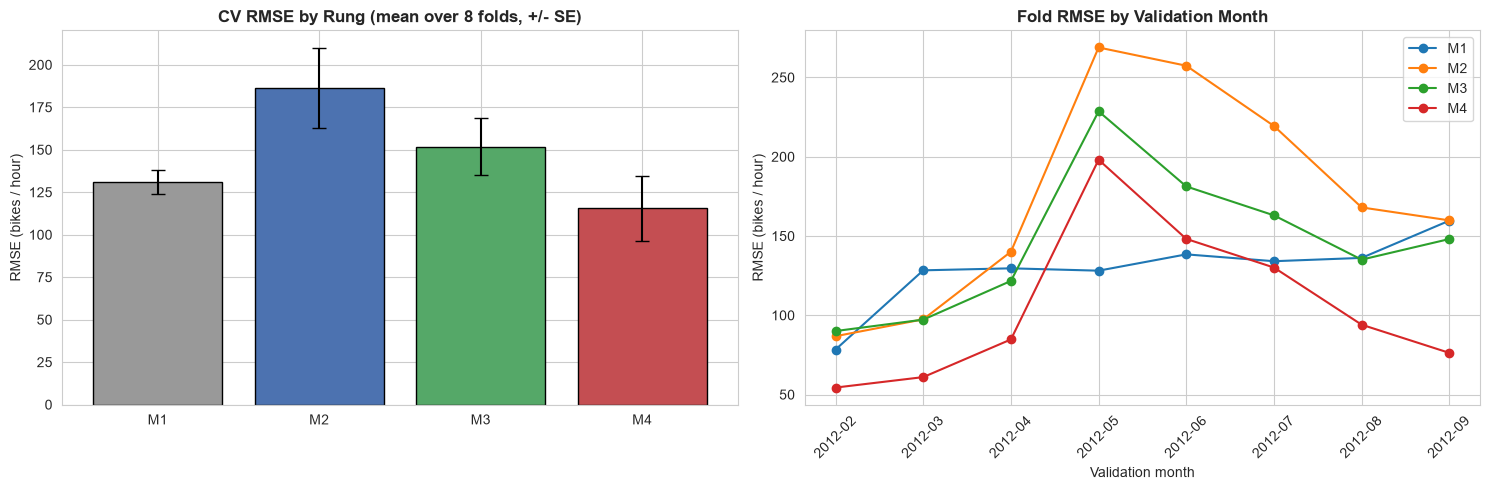

In [9]:
# Plot CV RMSE with SE bars and per-fold RMSE
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

rmse_se = cv_summary['se_mse'] / (2 * cv_summary['cv_rmse'])  # delta-method SE for RMSE
axes[0].bar(cv_summary.index, cv_summary['cv_rmse'], yerr=rmse_se, capsize=5,
            color=['#999999', '#4c72b0', '#55a868', '#c44e52'], edgecolor='black')
axes[0].set_title('CV RMSE by Rung (mean over 8 folds, +/- SE)', fontweight='bold')
axes[0].set_ylabel('RMSE (bikes / hour)')

for name, fr in fold_results.items():
    axes[1].plot(fr['val_month'], fr['rmse'], marker='o', label=name)
axes[1].set_title('Fold RMSE by Validation Month', fontweight='bold')
axes[1].set_xlabel('Validation month')
axes[1].set_ylabel('RMSE (bikes / hour)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
# Paired fold-by-fold gain of each rung vs the M1 baseline (positive = lower error than M1)
rows = []
for name in ['M2', 'M3', 'M4']:
    d = fold_results['M1']['mse'].to_numpy() - fold_results[name]['mse'].to_numpy()
    se = d.std(ddof=1) / np.sqrt(K)
    rows.append({'model': name, 'mean_gain_vs_M1': d.mean(), 'se': se, 'gain_in_SEs': d.mean() / se,
                 'folds_better_than_M1': int((d > 0).sum()),
                 'worse_in_months': ', '.join(fold_results['M1']['val_month'][d < 0])})
print("=== Paired gain vs M1 (count-scale MSE) ===")
print(pd.DataFrame(rows).set_index('model').round(2).to_string())

=== Paired gain vs M1 (count-scale MSE) ===
       mean_gain_vs_M1       se  gain_in_SEs  folds_better_than_M1                                                worse_in_months
model                                                                                                                            
M2           -17510.34  8396.04        -2.09                     1  2012-02, 2012-04, 2012-05, 2012-06, 2012-07, 2012-08, 2012-09
M3            -5903.50  4887.33        -1.21                     4                             2012-02, 2012-05, 2012-06, 2012-07
M4             3795.20  4552.67         0.83                     6                                               2012-05, 2012-06


In [11]:
# Bias by validation month: mean prediction / mean actual, with and without the sigma^2/2 correction
X_all = base_df[FEATURE_COLS]
y_all = base_df[TARGET].to_numpy()

rows = []
for name in ['M1', 'M2', 'M3', 'M4']:
    spec = MODEL_SPECS[name]
    for k, (tr, va) in enumerate(cv_splitter.split(base_df), start=1):
        pipe, s2 = fit_model(spec, X_all.iloc[tr], y_all[tr])
        corrected = predict_count(pipe, s2, X_all.iloc[va])
        uncorrected = np.exp(pipe.predict(X_all.iloc[va])) if spec['log_target'] else corrected
        rows.append({'model': name, 'val_month': base_df['dteday'].iloc[va].min().strftime('%Y-%m'),
                     'corrected': corrected.mean() / y_all[va].mean(),
                     'uncorrected': uncorrected.mean() / y_all[va].mean()})
bias = pd.DataFrame(rows)
print("Mean prediction / mean actual (1.00 = unbiased; > 1 over-predicts)\n")
print("With exp(sigma^2/2) correction:")
print(bias.pivot(index='val_month', columns='model', values='corrected').round(2).to_string())
print("\nWithout correction, exp(yhat) only:")
print(bias.pivot(index='val_month', columns='model', values='uncorrected').round(2).to_string())

Mean prediction / mean actual (1.00 = unbiased; > 1 over-predicts)

With exp(sigma^2/2) correction:
model        M1    M2    M3    M4
val_month                        
2012-02    0.97  1.19  1.22  1.18
2012-03    0.80  0.96  0.92  0.89
2012-04    0.93  1.30  1.22  1.17
2012-05    1.05  1.70  1.59  1.53
2012-06    0.99  1.51  1.37  1.32
2012-07    0.97  1.43  1.30  1.25
2012-08    0.94  1.28  1.18  1.14
2012-09    0.92  1.18  1.16  1.10

Without correction, exp(yhat) only:
model        M1    M2    M3    M4
val_month                        
2012-02    0.97  0.98  1.00  1.08
2012-03    0.80  0.78  0.76  0.82
2012-04    0.93  1.06  1.00  1.08
2012-05    1.05  1.38  1.30  1.40
2012-06    0.99  1.23  1.12  1.21
2012-07    0.97  1.17  1.07  1.15
2012-08    0.94  1.05  0.97  1.05
2012-09    0.92  0.97  0.96  1.02


### Interpretation & Modeling Decisions: CV Comparison
**Author**: Tee Jing Yuan 
<!-- Which rungs improved CV error by more than ~2 paired SEs? Did any rung fail to pay for its extra parameters? Are any folds much worse than others (e.g. Sep 2012, nearest to the locked test period)? -->
M4 has the lowest CV RMSE (115.5), compared with 130.9 for M1, 186.1 for M2 and 151.8 for M3. M4 beats M3 by 7.47 SE, which is a clear gain. Against M1, however, the gain is only 0.83 SE (M4 is better in 6 of 8 folds but worse in May and June), so CV alone cannot separate M1 and M4. The reason for choosing M4 is because it has no negative predictions and a much flatter hourly residual pattern.

It is noted that the log based models all spike in May (RMSE 269 for M2, 229 for M3, 198 for M4, against 128 for M1) while M1 stays flat. 

## 6. Diagnostic Verification of Resolved Mistakes
*Code: Generated by AI Assistant*

CV error says *whether* a rung is better; diagnostics say *why*. M1 and the final rung (`DIAG_MODEL`) are refitted on all training data and compared:
- **Residuals vs. Fitted** (+ lowess): curvature indicates unmodelled nonlinearity.
- **Normal Q-Q**: heavy tails / skew indicate non-normal errors.
- **Scale-Location** (+ lowess): a rising or falling smoother indicates non-constant variance (funnel).
- **Residuals vs. Leverage**: leverage $> 2(p+1)/n$, $|r^*| > 3$ and Cook's $D > 4/n$ are screens for points to investigate, not points to delete (D-04).
- **Supporting evidence** (after the plots): mean residual by hour $\times$ working day, negative predictions, and lag-1 residual autocorrelation.

Note: M1 diagnostics are on the `cnt` scale and M2 to M4 on the $\log(cnt)$ scale, since that is the scale on which each model's errors are assumed. Only the CV table in Section 5 is comparable across all rungs.

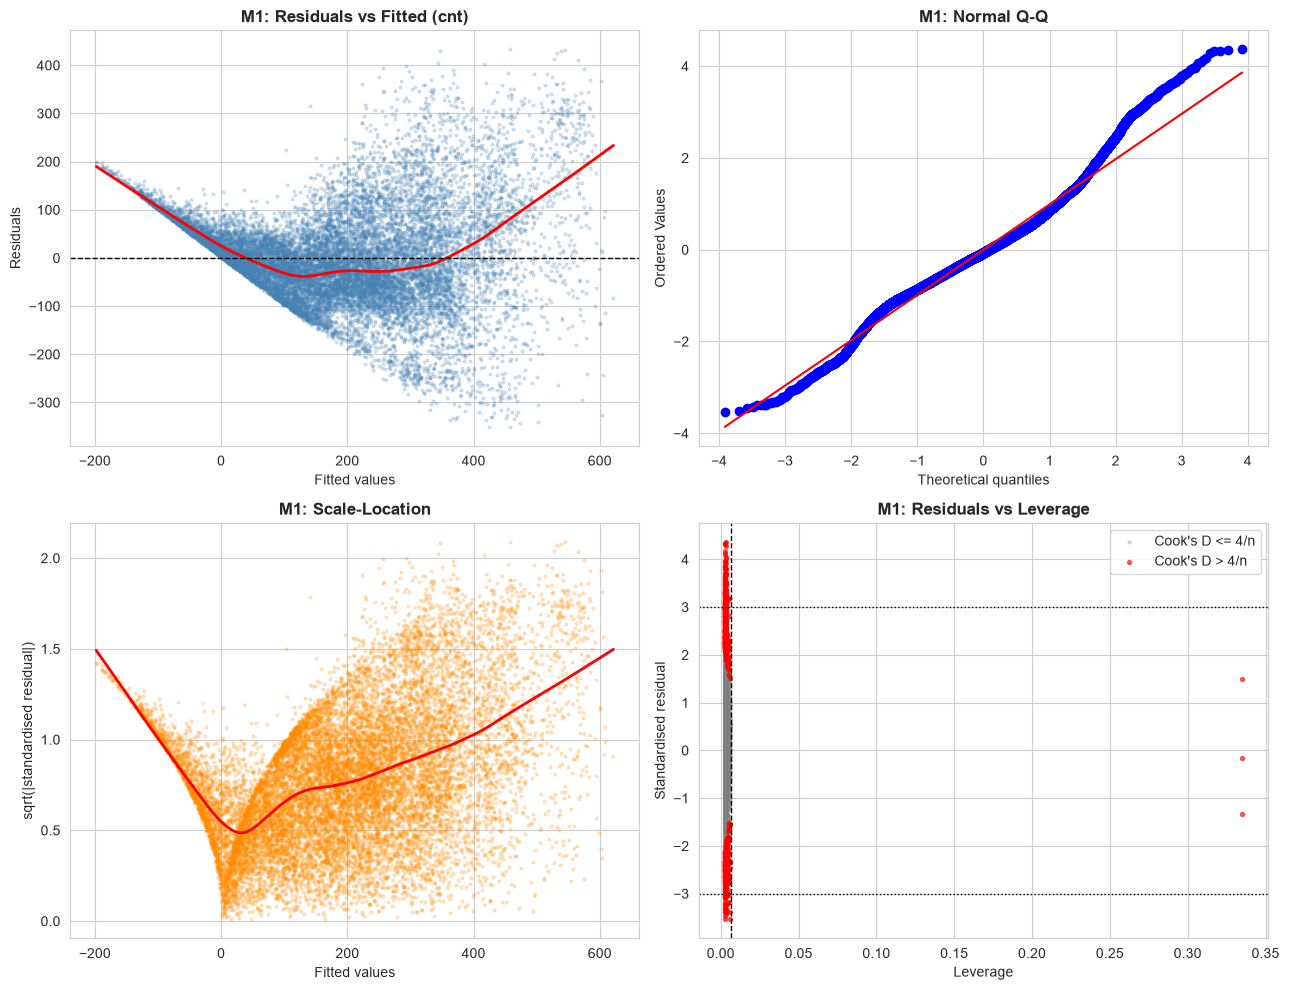

M1 (cnt): skew = 0.446, excess kurtosis = 1.544, max |std resid| = 4.37, #|std resid| > 3 = 200, #leverage > 2(p+1)/n = 5, #Cook's D > 4/n = 954


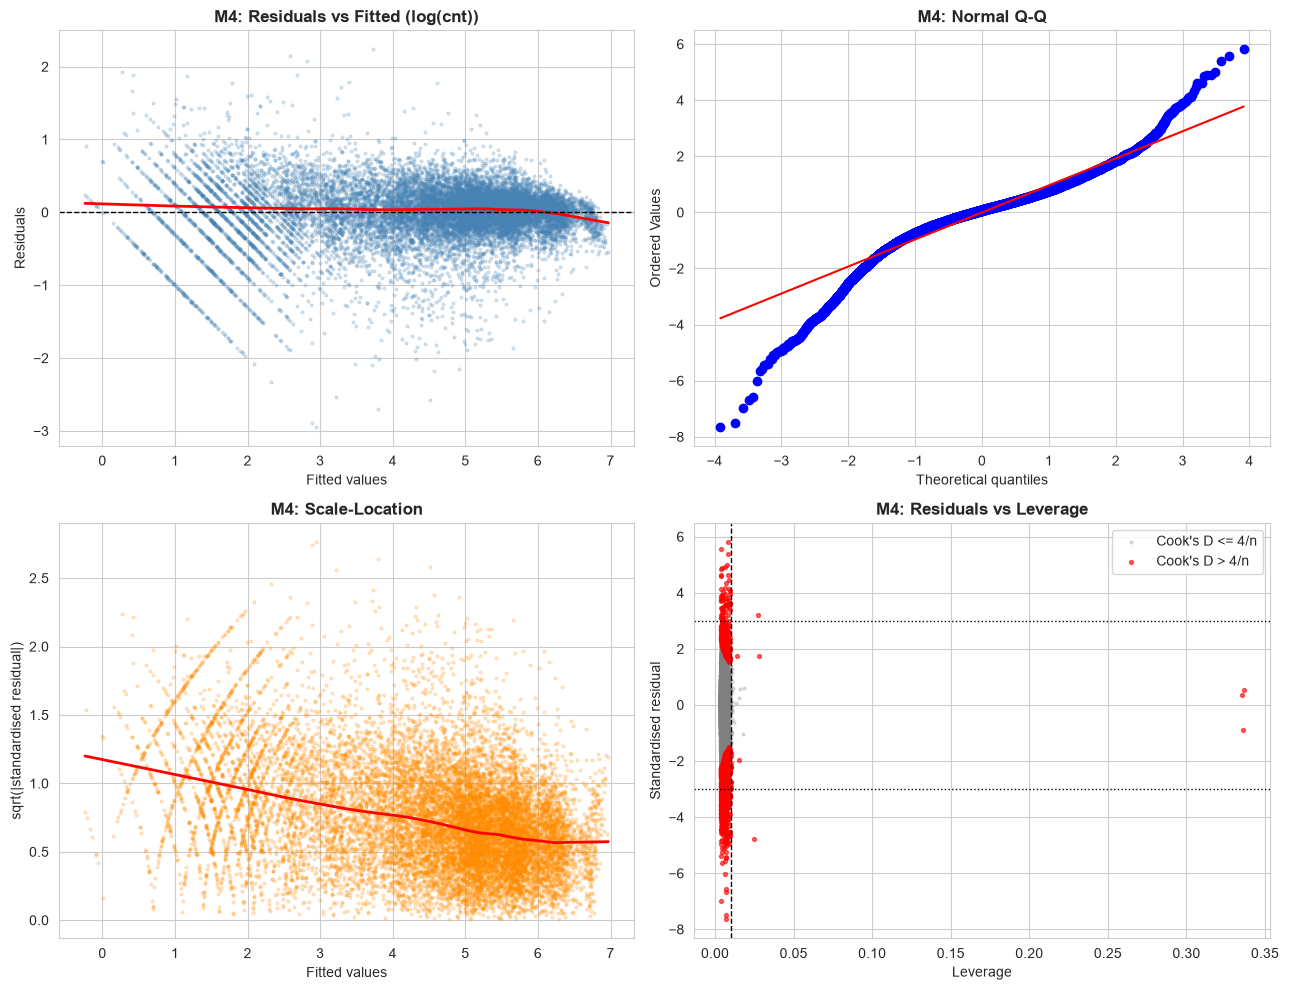

M4 (log(cnt)): skew = -0.882, excess kurtosis = 4.616, max |std resid| = 7.64, #|std resid| > 3 = 291, #leverage > 2(p+1)/n = 42, #Cook's D > 4/n = 901


In [12]:
# Four diagnostic plots 
import warnings
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence
from scipy import stats as scipy_stats

y_all = base_df[TARGET].to_numpy()
X_all = base_df[FEATURE_COLS]


def diagnostic_plots(name):
    spec = MODEL_SPECS[name]
    y_fit = np.log(y_all) if spec['log_target'] else y_all          # scale the model was fitted on
    scale = 'log(cnt)' if spec['log_target'] else 'cnt'

    # Refit with statsmodels on all training data (same design as the CV pipeline)
    pipe, _ = fit_model(spec, X_all, y_all)
    Xd = X_all if len(pipe.steps) == 1 else pipe[:-1].transform(X_all)
    model = sm.OLS(y_fit, sm.add_constant(np.asarray(Xd, dtype=float))).fit()   # full-rank design (holiday main effect dropped)

    influence = OLSInfluence(model)
    std_resid = influence.resid_studentized_internal               # standardised residuals
    fitted = model.fittedvalues
    leverage = influence.hat_matrix_diag
    cooks_d = influence.cooks_distance[0]
    n, p = int(model.nobs), int(model.df_model)

    fig, axes = plt.subplots(2, 2, figsize=(13, 10))

    # 1. Residuals vs fitted (+ lowess)
    lo = sm.nonparametric.lowess(model.resid, fitted, frac=0.3)
    axes[0, 0].scatter(fitted, model.resid, s=4, alpha=0.2, color='steelblue')
    axes[0, 0].plot(lo[:, 0], lo[:, 1], color='red', linewidth=2)
    axes[0, 0].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[0, 0].set_title(f'{name}: Residuals vs Fitted ({scale})', fontweight='bold')
    axes[0, 0].set_xlabel('Fitted values'); axes[0, 0].set_ylabel('Residuals')

    # 2. Normal Q-Q
    scipy_stats.probplot(std_resid, dist='norm', plot=axes[0, 1])
    axes[0, 1].set_title(f'{name}: Normal Q-Q', fontweight='bold')

    # 3. Scale-location (+ lowess)
    sqrt_abs = np.sqrt(np.abs(std_resid))
    lo = sm.nonparametric.lowess(sqrt_abs, fitted, frac=0.3)
    axes[1, 0].scatter(fitted, sqrt_abs, s=4, alpha=0.2, color='darkorange')
    axes[1, 0].plot(lo[:, 0], lo[:, 1], color='red', linewidth=2)
    axes[1, 0].set_title(f'{name}: Scale-Location', fontweight='bold')
    axes[1, 0].set_xlabel('Fitted values'); axes[1, 0].set_ylabel('sqrt(|standardised residual|)')

    # 4. Residuals vs leverage (Cook's D > 4/n highlighted)
    flag = cooks_d > 4 / n
    axes[1, 1].scatter(leverage[~flag], std_resid[~flag], s=4, alpha=0.25, color='gray', label="Cook's D <= 4/n")
    axes[1, 1].scatter(leverage[flag], std_resid[flag], s=8, alpha=0.6, color='red', label="Cook's D > 4/n")
    axes[1, 1].axvline(2 * (p + 1) / n, color='black', linestyle='--', linewidth=1)   # leverage threshold
    axes[1, 1].axhline(3, color='black', linestyle=':', linewidth=1)
    axes[1, 1].axhline(-3, color='black', linestyle=':', linewidth=1)
    axes[1, 1].set_title(f'{name}: Residuals vs Leverage', fontweight='bold')
    axes[1, 1].set_xlabel('Leverage'); axes[1, 1].set_ylabel('Standardised residual')
    axes[1, 1].legend()

    plt.tight_layout()
    plt.show()

    # Numbers to quote in the interpretation (pandas kurt() is EXCESS kurtosis)
    s = pd.Series(std_resid)
    print(f"{name} ({scale}): skew = {s.skew():.3f}, excess kurtosis = {s.kurt():.3f}, "
          f"max |std resid| = {np.abs(std_resid).max():.2f}, "
          f"#|std resid| > 3 = {(np.abs(std_resid) > 3).sum()}, "
          f"#leverage > 2(p+1)/n = {(leverage > 2 * (p + 1) / n).sum()}, "
          f"#Cook's D > 4/n = {flag.sum()}")


DIAG_MODEL = 'M4'
diagnostic_plots('M1')
diagnostic_plots(DIAG_MODEL)

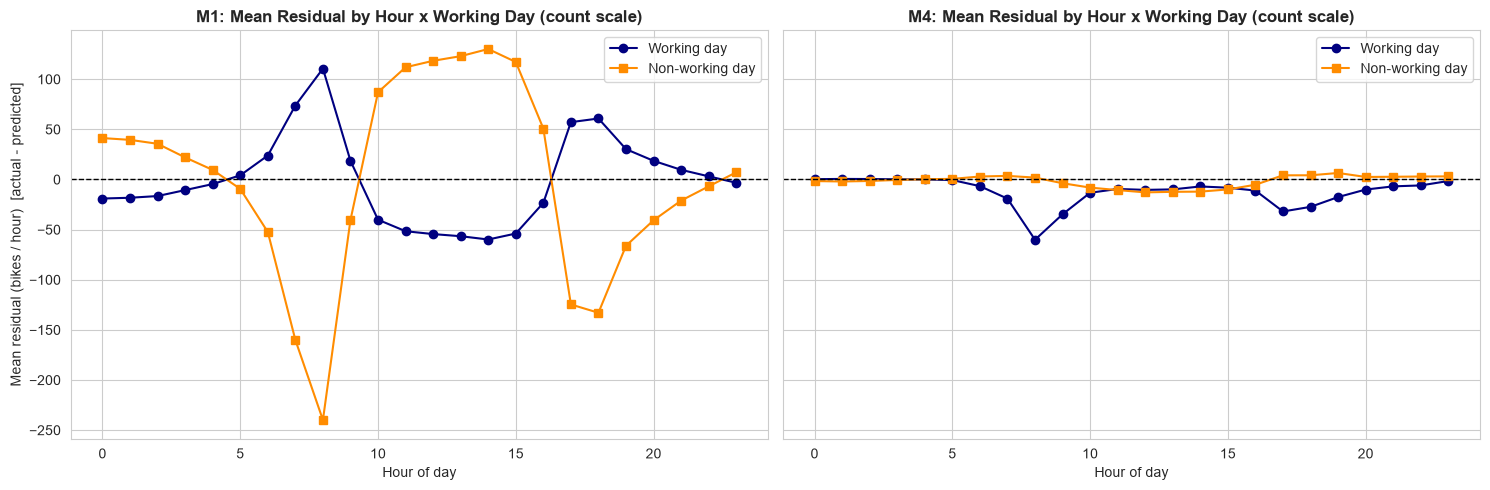

    negative_predictions  share_of_rows_%  lag1_resid_autocorr
M1                1597.0           10.499                0.751
M4                   0.0            0.000                0.522

Rows with weathersit = 4 (heavy rain / ice): 3


In [13]:
# Supporting evidence for Section 6: hour x working day residuals, negative predictions, residual autocorrelation
def count_scale_fit(name):
    spec = MODEL_SPECS[name]
    pipe, s2 = fit_model(spec, X_all, y_all)
    y_fit = np.log(y_all) if spec['log_target'] else y_all
    return {'count_pred': predict_count(pipe, s2, X_all),
            'fit_resid': y_fit - pipe.predict(X_all)}      # residual on the scale the model was fitted on

fits = {n: count_scale_fit(n) for n in ['M1', DIAG_MODEL]}
hour = (base_df[HR_COLS].to_numpy() * np.arange(1, 24)).sum(axis=1)     # hr_k dummies -> hour 0-23

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, name in zip(axes, ['M1', DIAG_MODEL]):
    res = pd.DataFrame({'hr': hour, 'workingday': base_df['workingday'].to_numpy(),
                        'resid': y_all - fits[name]['count_pred']})   # count scale, same units for both models
    prof = res.groupby(['hr', 'workingday'])['resid'].mean().unstack()
    ax.plot(prof.index, prof[1], marker='o', color='navy', label='Working day')
    ax.plot(prof.index, prof[0], marker='s', color='darkorange', label='Non-working day')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'{name}: Mean Residual by Hour x Working Day (count scale)', fontweight='bold')
    ax.set_xlabel('Hour of day'); ax.legend()
axes[0].set_ylabel('Mean residual (bikes / hour)  [actual - predicted]')
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    n: {'negative_predictions': int((f['count_pred'] < 0).sum()),
        'share_of_rows_%': 100 * (f['count_pred'] < 0).mean(),
        'lag1_resid_autocorr': np.corrcoef(f['fit_resid'][:-1], f['fit_resid'][1:])[0, 1]}
    for n, f in fits.items()}).T
print(summary.round(3).to_string())
print(f"\nRows with weathersit = 4 (heavy rain / ice): {int(base_df['weathersit_4'].sum())}")

### Interpretation & Modeling Decisions: Diagnostic Verification
**Author**: Tee Jing Yuan 
<!-- For each mistake in Section 2: resolved, partly resolved, or still present? Compare the M1 and final-rung plots and the negative-prediction / autocorrelation table. -->
Residuals vs Fitted: M1 has a clear U shaped curve and negative fitted values down to about -200. For M4 the line is flat around zero, so the non-linearity is resolved on the log scale. Negative predictions falls from 1,647 to 0.

Scale-Location: the funnel is reversed, not removed. The line falls from about 1.2 to 0.55, with more spread at low fitted values.

Q-Q: log fixed the right skew (0.44 to -0.89) but made the tails heavier as shown by excess kurtosis increasing 1.52 to 4.66. Coefficients stay unbiased, but exact t, F and interval results are approximate by CLT.

Leverage: Cook's D flags 919 points in M4 and 966 in M1, so the issue remained. Three points sit at leverage 0.335 in both models. They are the three weathersit = 4 (heavy rain) hours, with small residuals, so they are flagged for leverage rather than poor fit. To be kept and documented.

Overall, non-linearity and negative predictions are resolved, while heteroskedasticity, heavier tails and flagged points remain.

<!-- RECHECK after rerun: skew, kurtosis, Cook's D (966 / 919), leverage counts, lag-1 and 1,647 negatives come from full-training fits (03 now reports 1,597 negatives and 954 Cook's D flags for M1). -->

## Identification of remaining challenge

Rung scores from Section 5 are the candidate inputs to Workflow Step 6 (select one winner, refit on all training data). 

In [14]:
# Candidate summary for the team (input to Workflow Step 6)
print("=== Candidate Summary (shared CV, count-scale) ===")
print(cv_summary[['description', 'cv_rmse', 'se_mse', 'gain_vs_prev', 'gain_in_SEs', 'neg_preds']].round(2).to_string())
best = cv_summary['cv_mse'].idxmin()
print(f"\nLowest CV MSE: {best} ({cv_summary.loc[best, 'description']}). Final winner is chosen by the group in Workflow Step 6.")

=== Candidate Summary (shared CV, count-scale) ===
                               description  cv_rmse   se_mse  gain_vs_prev  gain_in_SEs  neg_preds
model                                                                                             
M1                    Base OLS (reference)   130.86  1882.65           NaN          NaN         37
M2                    M1 + log(cnt) target   186.11  8777.74     -17510.34        -2.09          0
M3     M2 + squared temp / hum / windspeed   151.75  5110.11      11606.84         2.69          0
M4                    M3 + hr x workingday   115.46  4376.27       9698.70         7.47          0

Lowest CV MSE: M4 (M3 + hr x workingday). Final winner is chosen by the group in Workflow Step 6.


### Interpretation & Modeling Decisions: Identification of remaining challenge
**Author**: Tee Jing Yuan
<!-- Concluding remarks: which rung(s) to carry forward, what Notebook 05 should address, and any caveats on the M1 reference score (replace with Notebook 03's recorded value). -->
We carry M4 forward as the candidate, with these caveats for Notebook 05 and the final selection:

-  M4 adds 23 interaction columns to 51 columns (48 base + 3 squared terms). If the gain over M1 does not justify them, regularisation should help.
- Correlation: residuals are still correlated between neighbouring hours (lag-1 of 0.75 for M1, 0.52 for M4 based on the Section 6 summary table). Because of strong correlation between the hours observations, the assumptions of iid observations are violated so standard errors would be smaller than the true SE. This causes t values to be inflated and reported p values to be smaller than the true p value
- Seasonal coverage: CV covers Feb to Sep 2012, but the locked test set is Oct to Dec 2012. The 2012 growth is captured by one yr term, so extrapolation into colder months is untested.
- Heavy rain: the weathersit = 4 effect rests on only 3 hours, so predictions for heavy rain are unreliable.

<!-- RECHECK after rerun: lag-1 autocorrelation (0.75 / 0.52) comes from full-training fits. -->